In [20]:
from langgraph.graph import StateGraph, START, END
from langchain_openai import ChatOpenAI
from typing import TypedDict
from dotenv import load_dotenv
load_dotenv()  # Load environment variables from .env file

True

In [21]:
model = ChatOpenAI(model_name="gpt-4o")

In [22]:
class BlogState(TypedDict):
    topic: str
    outline: str
    content: str
    score: str

In [23]:
def create_outline(state: BlogState) -> BlogState:

    topic = state['topic']

    prompt = f"Create a detailed outline for a blog post about: {topic}"
    outline = model.invoke(prompt).content

    state['outline'] = outline
    return state


In [24]:
def create_blog(state: BlogState) -> BlogState:

    outline  = state['outline']
    topic = state['topic']

    prompt = f'Write a detailed blog on the title - {topic} using the follwing outline \n {outline}'

    content = model.invoke(prompt).content

    state['content'] = content
    return state

In [25]:
def evaluate_blog(state: BlogState) -> BlogState:

    outline  = state['outline']

    content = state['content']

    prompt = f'Based on the following outline: {outline} and the blog content: {content}, provide a score from 1 to 10 for how well the blog content aligns with the outline and topic.'

    score = model.invoke(prompt).content

    state['score'] = score
    return state

In [26]:
graph = StateGraph(BlogState)

graph.add_node('create_outline', create_outline)
graph.add_node('create_blog', create_blog)
graph.add_node('evaluate_blog', evaluate_blog)

graph.add_edge(START, 'create_outline')
graph.add_edge('create_outline', 'create_blog')
graph.add_edge('create_blog', 'evaluate_blog')
graph.add_edge('evaluate_blog', END)

workflow = graph.compile()



In [27]:
initial_state = BlogState(topic="The Future of Artificial Intelligence")
final_state = workflow.invoke(initial_state)
print(final_state)  # This will print the final state with the outline, content, and score

{'topic': 'The Future of Artificial Intelligence', 'outline': "Title: The Future of Artificial Intelligence: Transformations, Opportunities, and Challenges\n\n---\n\n**Introduction**\n- Brief overview of Artificial Intelligence (AI) and its current state.\n- Explanation of AI’s growing impact on various industries.\n- Purpose of the blog: to explore potential future developments in AI.\n\n**1. The Current Landscape of AI**\n- Summary of recent advancements in AI technology.\n- Key industries utilizing AI today (e.g., healthcare, finance, automotive).\n- Examples of successful AI implementations.\n\n**2. Technological Advancements on the Horizon**\n- Emerging AI technologies (e.g., quantum computing-assisted AI, neuromorphic computing).\n- Enhanced machine learning techniques (e.g., unsupervised learning, reinforcement learning).\n- Developments in natural language processing and computer vision.\n\n**3. AI and Industry Transformation**\n- Discussion on how AI might reshape key industri

In [28]:
print(final_state['score'])

I would rate the blog content an 8 out of 10 in terms of alignment with the outline and topic. Here's a breakdown of the evaluation:

1. **Introduction**: The introduction effectively covers the brief overview of AI, its current impact, and sets the purpose of the blog appropriately, aligning well with the outlined goals.

2. **The Current Landscape of AI**: This section provides a clear summary of AI's recent advancements, key industries, and successful implementations, closely following the outline.

3. **Technological Advancements on the Horizon**: The content describes emerging technologies and advancements, adhering to the outline but could delve slightly deeper into each mentioned technology for full alignment.

4. **AI and Industry Transformation**: The discussion on industry transformation covers healthcare, transportation, manufacturing, and finance, and mentions AI-driven startups, well aligning with the outline.

5. **Societal Impacts of AI**: This section describes AI’s pot

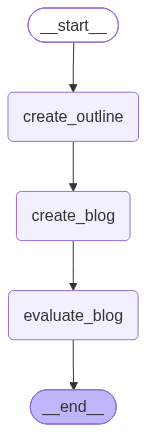

In [29]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())